# Environmental Programming
## Would These Temperatures Happen in a World Without Climate Change?

**Group 4** — Belgian Climate Change & Extreme Temperatures  
**Course:** Environmental Programming (VUB / IUPWARE, 2026–2027)

---

### Notebook Purpose (User Manual & Tutorial)
This Jupyter Notebook presents, documents, and executes our software for analysing extreme daily maximum temperatures in Belgium (**1960–2024**). It follows Assignment 4 step by step and is structured so our group can add Tasks 5–14 directly as we progress:

1. **Setup & Data Loading (Tasks 1–2):** Read monthly RMI gridded climate CSVs and convert them into an `xarray.DataArray` (`day` × `pixel`).
2. **Part 1 — Detection (Tasks 3–7):** Compute Belgium's annual hottest day (**TXx**), plot the time series, test for statistically significant warming trends (Mann-Kendall & Sen's slope), and map regional warming across Belgian provinces.
3. **Part 2 — Attribution (Tasks 8–14):** Quantify how human-induced global warming (using Berkeley Earth GMST) changed the probability and intensity of an extreme heat event and compare it with a moderate year.
4. **Optional Tasks:** Bootstrap 95% confidence intervals and/or interactive GUI.
5. **Project Documentation:** Code flowchart, Generative AI transparency log, and team contributions.

---

### Prerequisites & Folder Setup
1. Clone the repository using GitHub Desktop (`Group4-Belgian-Climate-Change`).
2. Activate the project Conda environment (see `environment.yml`). Core libraries used so far:
   - `pandas`, `numpy`, `xarray`, `matplotlib`
   - *(Upcoming tasks)*: `pymannkendall`, `scipy`, `geopandas`
3. Place the unzipped RMI monthly CSV folder (`climateGrid/`) inside the repository root (note: `climateGrid/` is excluded by `.gitignore` and is not stored on GitHub):

```text
Group4-Belgian-Climate-Change/
├── Group4_Climate_Change_Belgium.ipynb
├── climateGrid/                      # Local only (780 monthly CSV files: 196001–202412)
├── gmst_berkeley_preindustrial.csv   # Provided GMST data (for Part 2)
├── ne_10m_admin_1_states_provinces.* # Natural Earth shapefile (for maps)
└── environment.yml
```

> **Tip:** If your `climateGrid` folder is saved elsewhere on your PC, simply edit `DATA_FOLDER` in Section 0 below—or run the cell and paste your folder path when prompted.

## Code Flowchart *(Living Document — Update as Tasks Are Added)*

```text
[Monthly RMI CSVs: climategrid_YYYYMM.csv]
                   │
                   ▼
   Task 1: Locate & concatenate CSVs into DataFrame
                   │
                   ▼
   Task 2: Pivot to xarray.DataArray (day × pixel, datetime coords)
                   │
                   ▼
   Task 3: Spatial mean across Belgium → Annual max (TXx) + Hottest Date
                   │
                   ▼
   Task 4: Plot TXx time series (1960–2024)
                   │
         ┌─────────┴──────────┐
         ▼                    ▼
  [Upcoming: Tasks 5–7]  [Upcoming: Tasks 8–14]
  Mann-Kendall, Sen's    GMST linear fit, ±2σ band,
  slope & spatial map    normal curves, PR, ΔI & moderate year
```
*(Update or replace with a graphical diagram before the final submission.)*

---
## 0. Imports & Configuration

Run this cell first to load the required libraries and set dataset parameters. Keeping paths, filename patterns, and date ranges in one configuration cell makes the code flexible if tested on a different dataset or time period.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import pymannkendall as mk

# =============================================================================
# USER CONFIGURATION (Edit here if using a different folder or dataset)
# =============================================================================
# Default: looks for 'climateGrid' in the same folder as this notebook.
# To use a custom path, replace with e.g.: Path(r"C:\Users\YourName\Downloads\climateGrid")
DATA_FOLDER = Path.cwd() / "climateGrid"

FILE_PATTERN = "climategrid_*.csv"
CSV_SEPARATOR = ";"
START_YEAR_MONTH = "196001"
END_YEAR_MONTH = "202412"
EXPECTED_FILE_COUNT = 780  # 65 years * 12 months (set to None for a custom period)

# Spatial aggregation across Belgian pixels ('mean' = Belgium-wide daily average)
SPATIAL_AGGREGATION = "mean"

# Interactive fallback if the default folder is not found on a teammate's PC
while not DATA_FOLDER.is_dir():
    print(f"Folder not found: {DATA_FOLDER}")
    user_input = input("Enter the full path to your climateGrid folder: ").strip().strip('"')
    DATA_FOLDER = Path(user_input)

print(f"Using data folder: {DATA_FOLDER.resolve()}")


Using data folder: C:\Users\calvi\Desktop\GitHubRepos\Group4-Belgian-Climate-Change\climateGrid


---
## Part 1: Detection

### Task 1 — Read and Combine Monthly Climate Files (1960–2024)
We locate all monthly RMI files (`climategrid_YYYYMM.csv`) within the configured period, check that the expected number of files is present, and combine only the required columns (`pixel_id`, `day`, `temp_max`) using memory-efficient data types (`int16` and `float32`).

> **Workflow tip:** Loading 780 monthly CSV files is the slowest step. Run Tasks 1 and 2 **once** per session and keep `temp_max_xr` in memory while developing and testing later tasks.

In [3]:
#TASK 1: Read and combine monthly climate files (1960–2024)

# 1. Set your climateGrid folder path
# Works automatically if this notebook is inside the Group4-Belgian-Climate-Change folder:
folder = Path.cwd() / "climateGrid"

# If your folder is somewhere else, comment out the line above and uncomment the line below:
# folder = Path(r"C:\Users\calvi\Desktop\GitHubRepos\Group4-Belgian-Climate-Change\climateGrid")

files = [
    f for f in sorted(folder.rglob("climategrid_*.csv"))
    if "climategrid_196001.csv" <= f.name <= "climategrid_202412.csv"
]

if len(files) != 780:
    raise FileNotFoundError(f"Found {len(files)}/780 files in {folder}. Check your folder path.")

print(f"Found all {len(files)} files. Loading data...")

# 2. Read and combine only the 3 needed columns from every file
df = pd.concat(
    pd.read_csv(f, sep=";", usecols=["pixel_id", "day", "temp_max"], parse_dates=["day"])
    for f in files
)

print("Done! Loaded shape:", df.shape)

Found all 780 files. Loading data...
Done! Loaded shape: (32289120, 3)


### Task 2 — Convert to an `xarray.DataArray` (`day` × `pixel`)
As required by Task 2, we convert the combined table into a 2D `xarray.DataArray` of daily maximum temperature (`temp_max`) with dimensions **`day`** (in `datetime64` format) and **`pixel`**.

This `temp_max_xr` DataArray is used for **all subsequent tasks** (Belgian TXx, per-pixel warming maps, and event-day spatial maps).

In [4]:
#TASK 2: Reshape into a 2D array with dimensions (day, pixel)

# 3. Reshape into a 2D NumPy array with dimensions (day, pixel)
temp_max_array = df.pivot(index="day", columns="pixel_id", values="temp_max").to_numpy()


### Task 3 — Calculate the Hottest Day of Each Year (`TXx`) for Belgium
Using `temp_max_xr`, we calculate the Belgium-wide daily maximum temperature by averaging across all grid pixels (`dim="pixel"`), then extract:
1. **`TXx`**: the highest daily temperature in each year, and
2. **`Hottest_day`**: the exact date (`YYYY-MM-DD`) when that peak occurred.

In [6]:
#TASK 3: Find the hottest days

# 4. Calculate the mean temperature across all pixels for each day
daily_mean = df.groupby("day")["temp_max"].mean()

# 5. Find the highest daily mean temperature for each year (TXx)
TXx = daily_mean.groupby(daily_mean.index.year).max()

# 6. Find the date of the hottest day in each year
hottest_dates = daily_mean.groupby(daily_mean.index.year).idxmax()

# 7. Create a table with the results
results = pd.DataFrame({
    "Year": TXx.index,
    "Hottest_day": hottest_dates.values,
    "TXx": TXx.values
})

# 8. Display the results
print(results.to_string(index=False))

 Year Hottest_day       TXx
 1960  1960-06-23 28.118882
 1961  1961-07-01 31.339684
 1962  1962-09-03 27.507125
 1963  1963-07-22 28.938838
 1964  1964-08-26 32.186956
 1965  1965-08-05 26.440676
 1966  1966-08-13 30.318801
 1967  1967-07-13 30.739978
 1968  1968-07-02 32.252412
 1969  1969-07-23 30.374640
 1970  1970-07-07 29.265706
 1971  1971-07-09 29.554493
 1972  1972-07-19 30.397853
 1973  1973-07-05 30.614662
 1974  1974-08-15 29.591721
 1975  1975-08-04 32.916735
 1976  1976-07-03 34.844022
 1977  1977-06-13 30.663941
 1978  1978-07-30 31.068743
 1979  1979-07-28 28.408213
 1980  1980-08-02 29.941537
 1981  1981-08-06 29.998066
 1982  1982-07-09 32.004169
 1983  1983-07-31 31.864559
 1984  1984-07-30 32.173390
 1985  1985-07-14 29.233787
 1986  1986-08-03 32.243772
 1987  1987-08-21 29.786162
 1988  1988-08-18 27.898735
 1989  1989-07-22 33.095485
 1990  1990-08-04 34.448596
 1991  1991-07-11 32.103051
 1992  1992-08-08 31.593772
 1993  1993-06-09 29.927743
 1994  1994-08-04 34

### Task 4 — Plot `TXx` as a Time Series
We plot the annual `TXx` time series with a reusable plotting function so Task 6 can overlay the Sen's slope trend line onto the same figure without duplicating code.

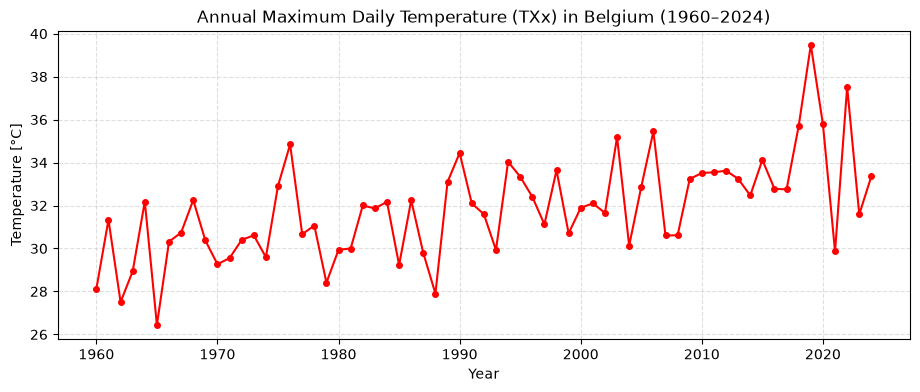

In [7]:
#TASK 4: Make a plot of the hottest days throughout the years

fig, ax = plt.subplots(figsize=(11, 4))

ax.plot(results["Year"], results["TXx"], color = "red", label = "Hottest days through out the years", marker = "o", markersize=4, linewidth=1.5)
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature [°C]")
ax.set_title("Annual Maximum Daily Temperature (TXx) in Belgium (1960–2024)")
plt.show()

### Task 5 — Mann-Kendall Trend Test & Sen's Slope *(To Do)*
*Next step:* Run `pymannkendall.original_test(results["TXx"])` to test whether `TXx` has changed significantly (`p < 0.05`) and report the warming rate (°C/year and °C/decade).

In [8]:
#TASK 5: Mann-Kendall test and Sen's slope

trend = mk.original_test(TXx)

print("P-value:", trend.p)
print("Sen's slope:", trend.slope, "°C/year")

if trend.p < 0.05:
    print("The trend is statistically significant.")
else:
    print("The trend is not statistically significant.")


P-value: 5.122983368632816e-07
Sen's slope: 0.07367676678229423 °C/year
The trend is statistically significant.


### Task 6 — Add Trend Line to the `TXx` Time Series
*Next step:* Compute the Sen's slope trend line from Task 5 and pass it into `plot_txx_timeseries(results, trend_line=..., trend_label=...)`.

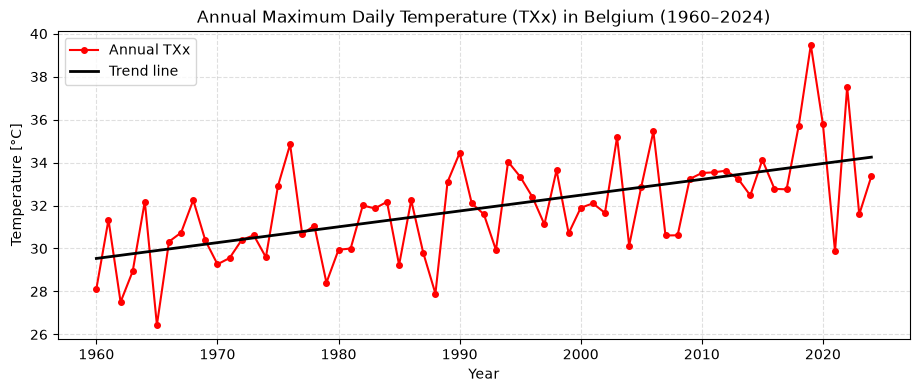

In [9]:
# TASK 6: Add the trend line to the plot
trendline = trend.slope * (results["Year"] - results["Year"].iloc[0]) + trend.intercept

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(results["Year"], results["TXx"], color="red", label="Annual TXx", marker="o", markersize=4, linewidth=1.5)
ax.plot(results["Year"], trendline, linewidth=2, color="black", label="Trend line")
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature [°C]")
ax.set_title("Annual Maximum Daily Temperature (TXx) in Belgium (1960–2024)")
ax.legend()
plt.show()

### Task 7 — Spatial Map of `TXx` Changes Across Belgium *(To Do)*
*Next step:* Compute per-pixel `TXx` changes from `temp_max_xr`, join pixel coordinates from the RMI metadata file, and map the result with Belgian and province boundaries (`ne_10m_admin_1_states_provinces.shp`) using `geopandas`. Discuss regional differences and why they occur.

Enter the full path to your metadata CSV file:  "C:\Users\calvi\Desktop\GitHubRepos\Group4-Belgian-Climate-Change\climateGrid\climategrid_pixel_metadata.csv"


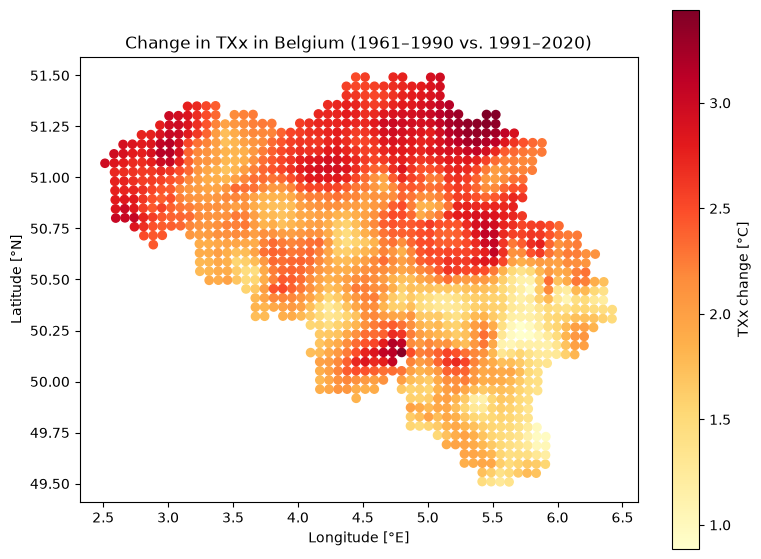

In [32]:
#TASK 7: Map of TXx changes in Belgium

# 1. Find the highest temperature for each pixel and year
df["year"] = df["day"].dt.year

annual = df.groupby(["year", "pixel_id"])["temp_max"].max().reset_index()

# 2. Calculate average TXx for two 30-year periods
old = annual[annual["year"].between(1961, 1990)]
new = annual[annual["year"].between(1991, 2020)]

old_mean = old.groupby("pixel_id")["temp_max"].mean()
new_mean = new.groupby("pixel_id")["temp_max"].mean()

# 3. Calculate temperature change
change = new_mean - old_mean

# 4. Read pixel coordinates from metadata
while True:
    metadata_path = Path(input("Enter the full path to your metadata CSV file: ").strip('"\' '))
    if metadata_path.is_file():
        break
    print("File not found. Please enter a valid full path to the metadata CSV file.")

metadata = pd.read_csv(metadata_path, sep=";")

# 5. Add temperature changes to coordinates
metadata["change"] = metadata["PIXEL_ID"].map(change)

# 6. Plot the map
plt.figure(figsize=(9, 7))

plt.scatter(
    metadata["PIXEL_LON_CENTER"],
    metadata["PIXEL_LAT_CENTER"],
    c=metadata["change"],
    cmap="YlOrRd",
    s=35
)

plt.colorbar(label="TXx change [°C]")
plt.xlabel("Longitude [°E]")
plt.ylabel("Latitude [°N]")
plt.title("Change in TXx in Belgium (1961–1990 vs. 1991–2020)")
plt.gca().set_aspect(1 / np.cos(np.deg2rad(50.5)), adjustable="box")
plt.show()

---
## Part 2: Attribution *(To Do)*

### Task 8 — Select an Extreme Event Year
*Next step:* Pick an exceptionally hot year (e.g., 2019) from `results` and report its exact date and temperature.

### Task 9 — Map Daily Maximum Temperature on the Event Day
*Next step:* Slice `temp_max_xr.sel(day=event_date)` and map the spatial distribution across Belgium.

### Task 10 — Linear Regression of `TXx` vs. GMST (Formulas 1 & 2)
*Next step:* Read `gmst_berkeley_preindustrial.csv`, leave out the event year, fit $TXx = \mu_0 + \alpha \cdot GMST + \varepsilon$, and compute $\sigma = \text{std}(\varepsilon)$.

### Task 11 — Plot `TXx` vs. GMST with $\pm 2\sigma$ Band and Event Marker
*Next step:* Plot the data points, fitted line, $\pm 2\sigma$ band, and event point; assess whether the event falls inside the band.

### Task 12 — Normal Distributions (Today vs. Pre-Industrial Climate)
*Next step:* Plot $\mathcal{N}(\mu_0, \sigma^2)$ and $\mathcal{N}(\mu_1, \sigma^2)$ together with a vertical line for the event temperature.

### Task 13 — Attribution Metrics (Formulas 3–6)
*Next step:* Compute exceedance probabilities ($p_1, p_0$), return periods ($T_1, T_0$), probability ratio ($PR = p_1 / p_0$), and intensity change ($\Delta I = \alpha \cdot GMST_{\text{event}}$), and comment on whether the event would have occurred without climate change.

### Task 14 — Repeat Attribution (Tasks 8–13) for a Moderate Year
*Next step:* Re-run the attribution pipeline for a moderate `TXx` year and compare how the metrics differ.

In [33]:
# TASK 8: Choose an event year with an exceptionally hot day
max_row = results.loc[results["TXx"].idxmax()]
event_year = int(max_row["Year"])
hottest_date = pd.to_datetime(max_row["Hottest_day"])
max_temp = float(max_row["TXx"])

print(f"Event year: {event_year}")
print(f"Hottest date: {hottest_date.date()}, Belgium mean TXx: {max_temp:.2f} °C")

Event year: 2019
Hottest date: 2019-07-25, Belgium mean TXx: 39.48 °C


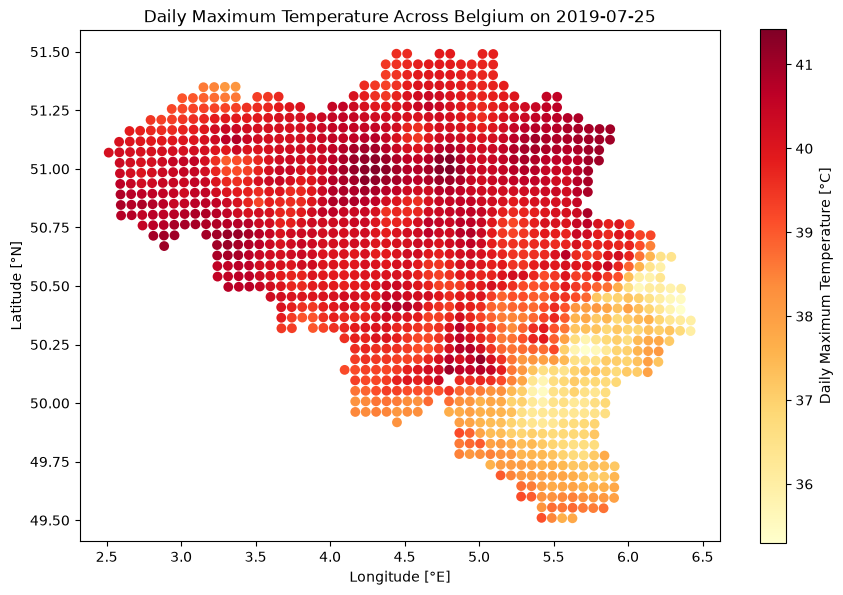

In [37]:
# TASK 9: Map of daily maximum temperature across Belgium on the event day
day_temps = df[df["day"] == hottest_date].set_index("pixel_id")["temp_max"]
metadata["hottest_day_temp"] = metadata["PIXEL_ID"].map(day_temps)

plt.figure(figsize=(9, 6.5))
plt.scatter(
    metadata["PIXEL_LON_CENTER"],
    metadata["PIXEL_LAT_CENTER"],
    c=metadata["hottest_day_temp"],
    cmap="YlOrRd",          # or "plasma_r" to match your Task 7 map
    s=50,
    edgecolors="none",
)

plt.colorbar(label="Daily Maximum Temperature [°C]", shrink=0.85)
plt.title(f"Daily Maximum Temperature Across Belgium on {hottest_date.date()}")
plt.xlabel("Longitude [°E]")
plt.ylabel("Latitude [°N]")
plt.gca().set_aspect(1 / np.cos(np.deg2rad(50.5)), adjustable="box")
plt.tight_layout()
plt.show()

---
## Optional Tasks *(If Implemented)*

### Optional Task 1 — Bootstrap Uncertainty Analysis (1,000 Resamples, 95% CI)
*Placeholder for resampling years with replacement, refitting Task 10, and reporting 2.5th–97.5th percentile confidence intervals.*

### Optional Task 2 — Graphical User Interface (GUI)
*Placeholder describing how to launch and use the GUI script (e.g., Tkinter).*

---
## Use of Generative AI *(Running Transparency Log)*

Update this table as the project progresses with detailed prompts and how your team tested and verified the generated code.

| Date | Tool | Task(s) | Detailed Sample Question / Prompt | How Output Was Used & Verified |
| :--- | :--- | :--- | :--- | :--- |
| 2026-11-23 | Gemini | Task 1 | *"Can you fix combineddata.py so that it will work for my classmates and have #notes for what to do to set it up for them since rn it's not working on their end?"* | Added relative path handling and `rglob` for nested folders; verified locally on team Windows PCs that all 780 files load cleanly. |
| 2026-11-24 | Gemini | Tasks 2–4 | *"Can you refine the title of this TXx plot code and create a starter Jupyter Notebook for what we have so far so we can keep adding to it?"* | Converted Task 2 to `xarray.DataArray` (`day` × `pixel`), aligned Task 3–4 numbering, refined plot formatting, and checked that annual TXx values match our previous plot. |
| *(Add new rows as you progress)* | | | | |

---
## Team Member Contributions *(Running Log)*

Update this table throughout the project to summarize each group member's work alongside the GitHub commit history.

| Team Member | Tasks / Components Contributed | Notes |
| :--- | :--- | :--- |
| Calvin | Task 1 (`combineddata.py`), Notebook setup, Tasks 2–4 integration | Repo setup & initial data pipeline |
| Amy | Tasks 2–4 (`workingcode.py`), TXx calculation & initial plot | Daily spatial mean TXx & plotting |
| Long | Tasks 7 | |
| Hien | *(Add tasks)* | |

---
## References & Data Sources
- **RMI Open Data:** Royal Meteorological Institute of Belgium — Daily gridded climate data (`climategrid_YYYYMM.csv`).
- **Berkeley Earth:** Global Mean Surface Temperature (GMST) relative to pre-industrial (1850–1900), 4-year running mean (`gmst_berkeley_preindustrial.csv`).
- **Natural Earth:** 1:10m Admin-1 States & Provinces shapefile (`ne_10m_admin_1_states_provinces.shp`).
- **Methodology:** Philip, S., Kew, S., van Oldenborgh, G. J., Otto, F., Vautard, R., van Der Wiel, K., ... & van Aalst, M. (2020). *A protocol for probabilistic extreme event attribution analyses.* Advances in Statistical Climatology, Meteorology and Oceanography, 6(2), 177–203.